In [1]:
!pip install google-api-python-client

In [2]:
from googleapiclient.discovery import build
import pandas as pd

In [3]:
from google.colab import userdata
from googleapiclient.discovery import build

API_KEY = userdata.get("YOUTUBE_API_KEY")

youtube = build(
    "youtube",
    "v3",
    developerKey=API_KEY
)

request = youtube.search().list(
    part="snippet",
    q="artificial intelligence",
    type="video",
    maxResults=5
)

response = request.execute()

for item in response["items"]:
    print(item["snippet"]["title"])

How books are being scanned and destroyed to train artificial intelligence • FRANCE 24 English
AI Simplified: 6 Concepts You Need to Know About Modern AI
What Is AI? | Artificial Intelligence | What is Artificial Intelligence? | AI In 5 Mins |Simplilearn
What Is AI? | Learn all about artificial intelligence
Bill Gates stakes reputation: AI is not like past tech


In [4]:
request = youtube.search().list(
    part="snippet",
    q="artificial intelligence",
    type="video",
    maxResults=50
)

response = request.execute()

video_ids = [
    item["id"]["videoId"]
    for item in response["items"]
]

print("Number of videos:", len(video_ids))

Number of videos: 50


In [5]:
stats_request = youtube.videos().list(
    part="snippet,statistics,contentDetails",
    id=",".join(video_ids)
)

stats_response = stats_request.execute()

print("Videos retrieved:", len(stats_response["items"]))

Videos retrieved: 50


In [6]:
import pandas as pd

data = []

for video in stats_response["items"]:

    statistics = video.get("statistics", {})
    content = video.get("contentDetails", {})
    snippet = video.get("snippet", {})

    data.append({
        "title": snippet.get("title"),
        "views": int(statistics.get("viewCount", 0)),
        "likes": int(statistics["likeCount"])
                 if "likeCount" in statistics else None,
        "comments": int(statistics["commentCount"])
                    if "commentCount" in statistics else None,
        "duration": content.get("duration")
    })

df = pd.DataFrame(data)

display(df.head(10))

,title,views,likes,comments,duration
0,AI Simplified: 6 Concepts You Need to Know Abo...,993743,8801,478.0,PT8M49S
1,Artificial Intelligence | 60 Minutes Full Epis...,9549365,96947,8095.0,PT53M30S
2,What Is AI? | Learn all about artificial intel...,617637,4396,0.0,PT5M21S
3,The 10 Stages of Artificial Intelligence,1744040,27879,2614.0,PT11M38S
4,What Is AI? | Artificial Intelligence | What i...,4020966,43421,3194.0,PT5M28S
5,"AI, Machine Learning, Deep Learning and Genera...",3738392,78540,2252.0,PT10M1S
6,Artificial Intelligence: Last Week Tonight wit...,11650589,204762,11302.0,PT27M53S
7,Bill Gates stakes reputation: AI is not like p...,2710682,13685,5608.0,PT9M22S
8,"AI Expert WARNS: ""You're Not Ready For 2027""",4349089,27324,3234.0,PT20M3S
9,Artificial Intelligence: Complete path to 2030,495348,4949,349.0,PT2H1M27S


In [7]:
df.to_csv("youtube_ai_dataset.csv", index=False)

from google.colab import files
files.download("youtube_ai_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
from googleapiclient.discovery import build
from google.colab import userdata

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import isodate

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import gradio as gr

print("All libraries imported successfully!")

All libraries imported successfully!


In [9]:
pip install isodate


In [11]:
API_KEY = userdata.get("YOUTUBE_API_KEY")

youtube = build(
    "youtube",
    "v3",
    developerKey=API_KEY
)

print("YouTube API client created successfully!")

YouTube API client created successfully!


In [12]:
search_query = "artificial intelligence"
target_videos = 500

video_ids = []
next_page_token = None

while len(video_ids) < target_videos:

    request = youtube.search().list(
        part="snippet",
        q=search_query,
        type="video",
        maxResults=50,
        pageToken=next_page_token
    )

    response = request.execute()

    for item in response.get("items", []):
        video_id = item["id"]["videoId"]

        if video_id not in video_ids:
            video_ids.append(video_id)

    next_page_token = response.get("nextPageToken")

    print("Collected videos:", len(video_ids))

    if not next_page_token:
        break

video_ids = video_ids[:target_videos]

print("Total unique videos collected:", len(video_ids))

Collected videos: 50
Collected videos: 100
Collected videos: 146
Collected videos: 187
Collected videos: 236
Collected videos: 285
Collected videos: 316
Collected videos: 358
Collected videos: 400
Collected videos: 450
Collected videos: 499
Collected videos: 539
Total unique videos collected: 500


In [13]:
data = []

for i in range(0, len(video_ids), 50):

    batch_ids = video_ids[i:i+50]

    request = youtube.videos().list(
        part="snippet,statistics,contentDetails",
        id=",".join(batch_ids)
    )

    response = request.execute()

    for video in response.get("items", []):

        statistics = video.get("statistics", {})
        snippet = video.get("snippet", {})
        content = video.get("contentDetails", {})

        data.append({
            "video_id": video["id"],
            "title": snippet.get("title"),
            "channel": snippet.get("channelTitle"),
            "published_at": snippet.get("publishedAt"),
            "views": int(statistics["viewCount"])
                     if "viewCount" in statistics else np.nan,
            "likes": int(statistics["likeCount"])
                     if "likeCount" in statistics else np.nan,
            "comments": int(statistics["commentCount"])
                        if "commentCount" in statistics else np.nan,
            "duration": content.get("duration")
        })

df = pd.DataFrame(data)

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (500, 8)


,video_id,title,channel,published_at,views,likes,comments,duration
0,mUw27wG7uFA,AI Simplified: 6 Concepts You Need to Know Abo...,IBM Technology,2026-09-06T11:00:09Z,993768,8802.0,478.0,PT8M49S
1,aZ5EsdnpLMI,Artificial Intelligence | 60 Minutes Full Epis...,60 Minutes,2023-12-30T13:00:02Z,9549375,96947.0,8095.0,PT53M30S
2,JcXKbUIebrU,What Is AI? | Learn all about artificial intel...,Learn Bright,2024-12-05T16:00:26Z,617637,4396.0,0.0,PT5M21S
3,tFx_UNW9I1U,The 10 Stages of Artificial Intelligence,Future Business Tech,2023-10-28T10:00:46Z,1744040,27879.0,2614.0,PT11M38S
4,ad79nYk2keg,What Is AI? | Artificial Intelligence | What i...,Simplilearn,2019-04-30T14:30:01Z,4020973,43421.0,3194.0,PT5M28S


In [14]:
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (500, 8)


,video_id,title,channel,published_at,views,likes,comments,duration
0,mUw27wG7uFA,AI Simplified: 6 Concepts You Need to Know Abo...,IBM Technology,2026-09-06T11:00:09Z,993768,8802.0,478.0,PT8M49S
1,aZ5EsdnpLMI,Artificial Intelligence | 60 Minutes Full Epis...,60 Minutes,2023-12-30T13:00:02Z,9549375,96947.0,8095.0,PT53M30S
2,JcXKbUIebrU,What Is AI? | Learn all about artificial intel...,Learn Bright,2024-12-05T16:00:26Z,617637,4396.0,0.0,PT5M21S
3,tFx_UNW9I1U,The 10 Stages of Artificial Intelligence,Future Business Tech,2023-10-28T10:00:46Z,1744040,27879.0,2614.0,PT11M38S
4,ad79nYk2keg,What Is AI? | Artificial Intelligence | What i...,Simplilearn,2019-04-30T14:30:01Z,4020973,43421.0,3194.0,PT5M28S


In [15]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Dataset Shape: (500, 8)

Column Names:
['video_id', 'title', 'channel', 'published_at', 'views', 'likes', 'comments', 'duration']

Data Types:
video_id         object
title            object
channel          object
published_at     object
views             int64
likes           float64
comments        float64
duration         object
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   video_id      500 non-null    object 
 1   title         500 non-null    object 
 2   channel       500 non-null    object 
 3   published_at  500 non-null    object 
 4   views         500 non-null    int64  
 5   likes         484 non-null    float64
 6   comments      485 non-null    float64
 7   duration      500 non-null    object 
dtypes: float64(2), int64(1), object(5)
memory usage: 31.4+ KB


In [16]:
df[["views", "likes", "comments"]].describe().round(2)

,views,likes,comments
count,5.000000e+02,484.00,485.00
mean,2.491040e+06,34703.65,2001.15
std,2.015379e+07,129235.36,5942.44
min,1.000000e+00,0.00,0.00
25%,2.862975e+04,477.25,22.00
50%,2.786880e+05,3429.50,203.00
75%,1.437062e+06,20405.25,1226.00
max,4.425673e+08,1964573.00,67803.00


In [17]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
video_id         0
title            0
channel          0
published_at     0
views            0
likes           16
comments        15
duration         0
dtype: int64


In [18]:
print("\nMissing Values Percentage:")
print((df.isnull().mean() * 100).round(2))


Missing Values Percentage:
video_id        0.0
title           0.0
channel         0.0
published_at    0.0
views           0.0
likes           3.2
comments        3.0
duration        0.0
dtype: float64


In [19]:
print("\nDuplicate Video IDs:")
print(df["video_id"].duplicated().sum())


Duplicate Video IDs:
0


In [20]:
print("\nTotal Rows:", len(df))


Total Rows: 500


In [21]:
df_clean = df.copy()

print("Original Dataset:", df.shape)
print("Clean Dataset:", df_clean.shape)

Original Dataset: (500, 8)
Clean Dataset: (500, 8)


In [22]:
columns_to_fill = ["likes", "comments"]

for col in columns_to_fill:

    median_value = df_clean[col].median()

    df_clean[col] = df_clean[col].fillna(
        median_value
    )

    print(f"{col} median: {median_value}")

print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum())

likes median: 3429.5
comments median: 203.0

Missing Values After Cleaning:
video_id        0
title           0
channel         0
published_at    0
views           0
likes           0
comments        0
duration        0
dtype: int64


In [23]:
import isodate
import numpy as np

df_clean["duration_seconds"] = df_clean["duration"].apply(
    lambda x: isodate.parse_duration(x).total_seconds()
    if pd.notna(x) else np.nan
)

display(
    df_clean[
        ["title", "duration", "duration_seconds"]
    ].head()
)

,title,duration,duration_seconds
0,AI Simplified: 6 Concepts You Need to Know Abo...,PT8M49S,529.0
1,Artificial Intelligence | 60 Minutes Full Epis...,PT53M30S,3210.0
2,What Is AI? | Learn all about artificial intel...,PT5M21S,321.0
3,The 10 Stages of Artificial Intelligence,PT11M38S,698.0
4,What Is AI? | Artificial Intelligence | What i...,PT5M28S,328.0


In [24]:
features = [
    "views",
    "likes",
    "comments",
    "duration_seconds"
]

print("Dataset Shape:")
print(df_clean.shape)

print("\nMissing Values:")
print(df_clean[features].isnull().sum())

print("\nNegative Values:")
print((df_clean[features] < 0).sum())

print("\nDuplicate Videos:")
print(df_clean["video_id"].duplicated().sum())

Dataset Shape:
(500, 9)

Missing Values:
views               0
likes               0
comments            0
duration_seconds    0
dtype: int64

Negative Values:
views               0
likes               0
comments            0
duration_seconds    0
dtype: int64

Duplicate Videos:
0


In [25]:
print("Skewness Before Transformation:")

print(
    df_clean[features]
    .skew()
    .round(2)
)

Skewness Before Transformation:
views               21.00
likes                9.76
comments             6.24
duration_seconds     6.08
dtype: float64


In [26]:
import numpy as np

df_log = df_clean[features].apply(np.log1p)

print("Skewness Before Transformation:")
print(df_clean[features].skew().round(2))

print("\nSkewness After Transformation:")
print(df_log.skew().round(2))

Skewness Before Transformation:
views               21.00
likes                9.76
comments             6.24
duration_seconds     6.08
dtype: float64

Skewness After Transformation:
views              -0.87
likes              -0.66
comments           -0.20
duration_seconds    0.13
dtype: float64


In [27]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(df_log)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features,
    index=df_clean.index
)

print("First 5 Rows After Scaling:")
display(X_scaled_df.head())

print("\nMeans After Scaling:")
print(X_scaled_df.mean().round(3))

print("\nStandard Deviations After Scaling:")
print(X_scaled_df.std(ddof=0).round(3))

First 5 Rows After Scaling:


,views,likes,comments,duration_seconds
0,0.621048,0.439551,0.422380,0.248250
1,1.402403,1.294156,1.477655,1.179773
2,0.456815,0.192272,-1.881074,-0.009431
3,0.815273,0.850209,1.055867,0.391368
4,1.103722,1.008036,1.130634,0.001690



Means After Scaling:
views              -0.0
likes               0.0
comments            0.0
duration_seconds    0.0
dtype: float64

Standard Deviations After Scaling:
views               1.0
likes               1.0
comments            1.0
duration_seconds    1.0
dtype: float64


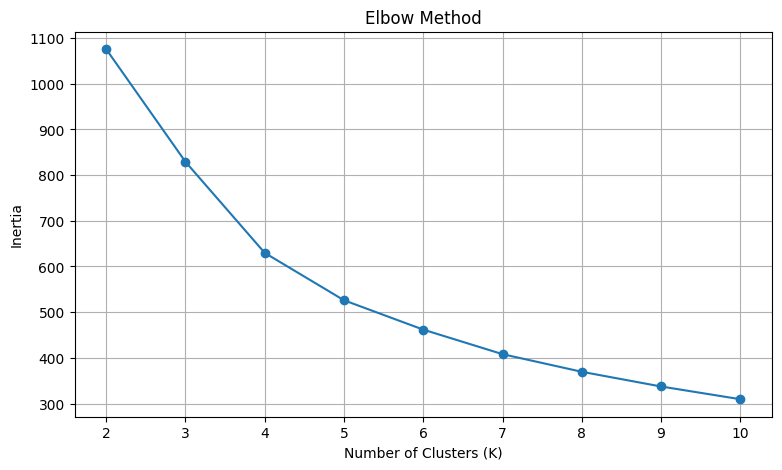

In [28]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

K_values = range(2, 11)
inertias = []

for k in K_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertias.append(model.inertia_)

plt.figure(figsize=(9, 5))

plt.plot(K_values, inertias, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(K_values))
plt.grid(True)

plt.show()

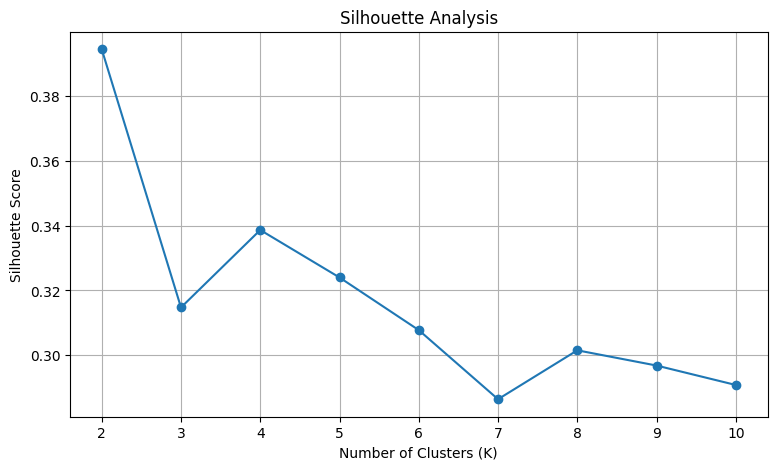

Best K: 2
Best Silhouette Score: 0.3945501262618485


In [29]:
from sklearn.metrics import silhouette_score
import numpy as np

silhouette_scores = []

for k in K_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

plt.figure(figsize=(9, 5))

plt.plot(
    K_values,
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")
plt.xticks(list(K_values))
plt.grid(True)

plt.show()

best_k = list(K_values)[np.argmax(silhouette_scores)]

print("Best K:", best_k)
print("Best Silhouette Score:", max(silhouette_scores))

In [30]:
final_k = 2

final_model = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

df_clean["cluster"] = final_model.fit_predict(X_scaled)

print("K-Means model trained successfully!")

print("\nNumber of videos in each cluster:")
print(df_clean["cluster"].value_counts().sort_index())

K-Means model trained successfully!

Number of videos in each cluster:
cluster
0    294
1    206
Name: count, dtype: int64


In [31]:
cluster_summary = df_clean.groupby("cluster").agg(
    number_of_videos=("video_id", "count"),
    avg_views=("views", "mean"),
    median_views=("views", "median"),
    avg_likes=("likes", "mean"),
    avg_comments=("comments", "mean"),
    avg_duration_seconds=("duration_seconds", "mean")
)

display(cluster_summary.round(2))

,number_of_videos,avg_views,median_views,avg_likes,avg_comments,avg_duration_seconds
cluster,,,,,,
0,294,4157472.20,1017165.5,56495.92,3284.35,2610.93
1,206,112734.63,21439.5,1173.01,38.86,662.48


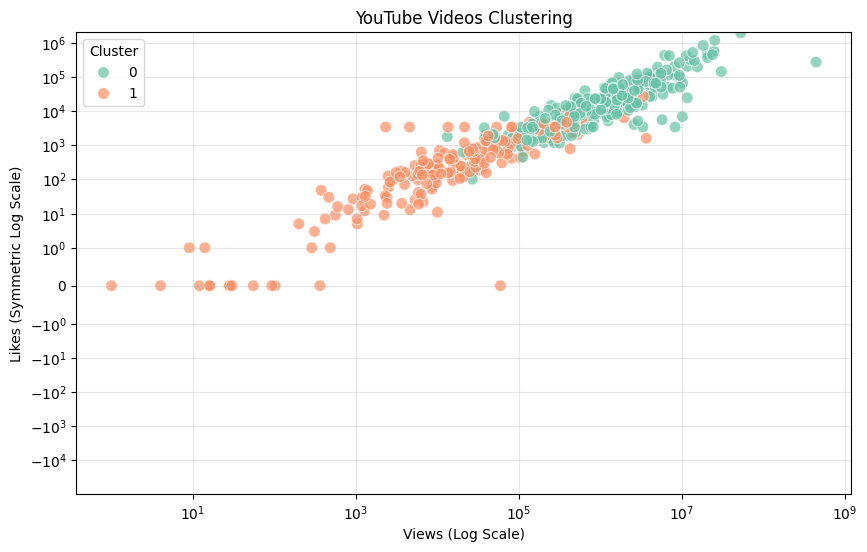

In [32]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="views",
    y="likes",
    hue="cluster",
    palette="Set2",
    s=70,
    alpha=0.7
)

plt.xscale("log")
plt.yscale("symlog", linthresh=1)

plt.title("YouTube Videos Clustering")
plt.xlabel("Views (Log Scale)")
plt.ylabel("Likes (Symmetric Log Scale)")
plt.legend(title="Cluster")
plt.grid(True, alpha=0.3)

plt.show()

In [33]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in [2, 4]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    print(f"\nK = {k}")
    print("Silhouette:", round(silhouette_score(X_scaled, labels), 4))
    print("Inertia:", round(model.inertia_, 2))

    comparison = df_clean.copy()
    comparison["cluster_test"] = labels

    summary = comparison.groupby("cluster_test").agg(
        videos=("video_id", "count"),
        avg_views=("views", "mean"),
        avg_likes=("likes", "mean"),
        avg_comments=("comments", "mean"),
        avg_duration=("duration_seconds", "mean")
    )

    display(summary.round(2))


K = 2
Silhouette: 0.3946
Inertia: 1075.57


,videos,avg_views,avg_likes,avg_comments,avg_duration
cluster_test,,,,,
0,294,4157472.20,56495.92,3284.35,2610.93
1,206,112734.63,1173.01,38.86,662.48



K = 4
Silhouette: 0.3387
Inertia: 629.68


,videos,avg_views,avg_likes,avg_comments,avg_duration
cluster_test,,,,,
0,184,6297157.16,86132.36,5070.33,2054.78
1,145,423999.90,5426.59,104.07,81.31
2,60,3625.85,40.52,19.93,160.85
3,111,226537.89,1926.13,219.63,4545.61


In [34]:
final_k = 4

final_model = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

df_clean["cluster"] = final_model.fit_predict(X_scaled)

print("Final K-Means Model: K =", final_k)

print("\nVideos per Cluster:")
print(df_clean["cluster"].value_counts().sort_index())

Final K-Means Model: K = 4

Videos per Cluster:
cluster
0    184
1    145
2     60
3    111
Name: count, dtype: int64


In [35]:
cluster_summary = df_clean.groupby("cluster").agg(
    videos=("video_id", "count"),
    avg_views=("views", "mean"),
    avg_likes=("likes", "mean"),
    avg_comments=("comments", "mean"),
    avg_duration=("duration_seconds", "mean")
)

display(cluster_summary.round(2))

,videos,avg_views,avg_likes,avg_comments,avg_duration
cluster,,,,,
0,184,6297157.16,86132.36,5070.33,2054.78
1,145,423999.90,5426.59,104.07,81.31
2,60,3625.85,40.52,19.93,160.85
3,111,226537.89,1926.13,219.63,4545.61


Although K=2 achieved the highest Silhouette Score (0.3946), K=4 was selected because it provided more interpretable and detailed video segments. The four clusters revealed meaningful differences in video reach, engagement, and duration, including short-form and long-form video groups.

In [36]:
# New video data
new_video = pd.DataFrame([{
    "views": 1000000,
    "likes": 15000,
    "comments": 700,
    "duration_seconds": 15 * 60
}])

# Apply Log Transformation
new_video_log = np.log1p(new_video[features])

# Apply the same fitted scaler
new_video_scaled = scaler.transform(new_video_log)

# Predict the cluster
predicted_cluster = final_model.predict(new_video_scaled)[0]

print("Predicted Cluster:", predicted_cluster)

Predicted Cluster: 0


In [37]:
cluster_names = {
    0: "High-Reach Videos",
    1: "Short Videos with Moderate Reach",
    2: "Low-Reach Videos",
    3: "Long-Form Videos with Moderate Reach"
}

cluster_id = int(predicted_cluster)

print("Predicted Cluster:", cluster_id)
print("Cluster Description:", cluster_names[cluster_id])

Predicted Cluster: 0
Cluster Description: High-Reach Videos


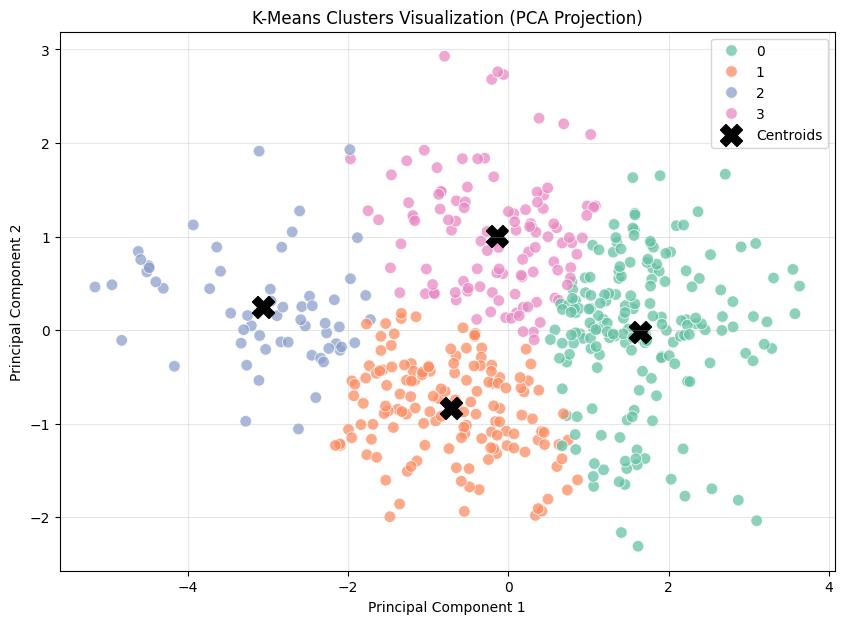

In [41]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Reduce the scaled data from 4 dimensions to 2 dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create a dataframe for plotting
plot_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
plot_df["cluster"] = df_clean["cluster"]

# Transform cluster centers to PCA space
centers_pca = pca.transform(final_model.cluster_centers_)

# Plot
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="Set2",
    s=70,
    alpha=0.75
)

# Plot centroids
plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    c="black",
    s=250,
    marker="X",
    label="Centroids"
)

plt.title("K-Means Clusters Visualization (PCA Projection)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

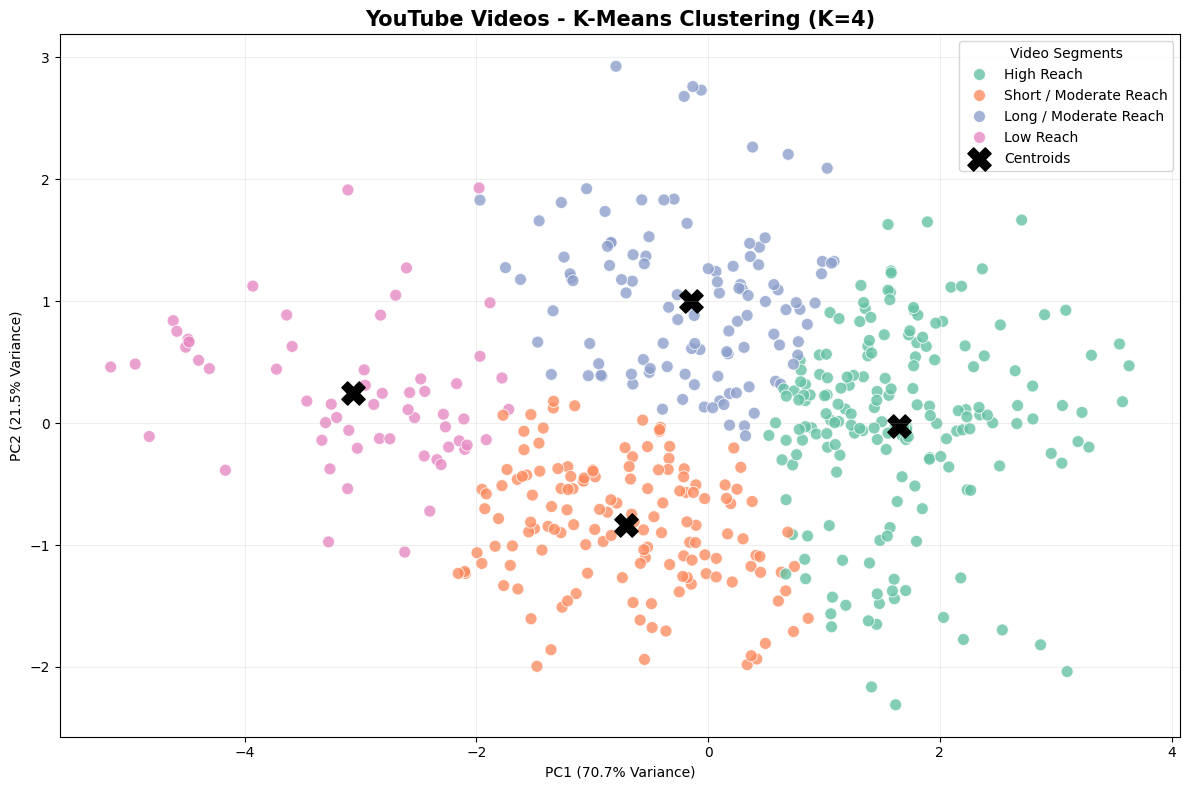

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

cluster_labels = {
    0: "High Reach",
    1: "Short / Moderate Reach",
    2: "Low Reach",
    3: "Long / Moderate Reach"
}

plot_df["cluster_name"] = plot_df["cluster"].map(cluster_labels)

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="cluster_name",
    palette="Set2",
    s=75,
    alpha=0.8
)

plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    c="black",
    marker="X",
    s=280,
    label="Centroids"
)

variance = pca.explained_variance_ratio_ * 100

plt.xlabel(f"PC1 ({variance[0]:.1f}% Variance)")
plt.ylabel(f"PC2 ({variance[1]:.1f}% Variance)")

plt.title(
    "YouTube Videos - K-Means Clustering (K=4)",
    fontsize=15,
    fontweight="bold"
)

plt.legend(title="Video Segments")
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "KMeans_PCA_Visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [46]:
import gradio as gr
import pandas as pd
import numpy as np

cluster_names = {
    0: "High-Reach Videos",
    1: "Short Videos with Moderate Reach",
    2: "Low-Reach Videos",
    3: "Long-Form Videos with Moderate Reach"
}

def predict_video_cluster(views, likes, comments, duration):

    # Validate inputs
    values = [views, likes, comments, duration]

    if any(v is None or not np.isfinite(v) or v < 0 for v in values):
        return "Please enter valid non-negative numbers."

    # Create DataFrame
    new_video = pd.DataFrame([{
        "views": views,
        "likes": likes,
        "comments": comments,
        "duration_seconds": duration * 60
    }])

    # Log Transformation
    new_video_log = np.log1p(new_video[features])

    # Scaling using the trained scaler
    new_video_scaled = scaler.transform(new_video_log)

    # Predict using the trained K-Means model
    cluster = int(final_model.predict(new_video_scaled)[0])

    return (
        f"Predicted Cluster: {cluster}\n"
        f"Category: {cluster_names[cluster]}"
    )

In [39]:
demo = gr.Interface(
    fn=predict_video_cluster,

    inputs=[
        gr.Number(label="Video Views", value=100000),
        gr.Number(label="Video Likes", value=5000),
        gr.Number(label="Video Comments", value=200),
        gr.Number(label="Video Duration (Minutes)", value=10)
    ],

    outputs=gr.Textbox(
        label="Clustering Result",
        lines=3
    ),

    title="YouTube Video K-Means Clustering",

    description=(
        "Enter YouTube video statistics to identify "
        "which of the four clusters the video belongs to."
    ),

    examples=[
        [1000, 30, 5, 3],
        [100000, 2500, 120, 8],
        [1000000, 15000, 700, 15],
        [5000000, 80000, 4500, 45]
    ]
)

In [54]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA

# PCA for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Project cluster centers
centers_pca = pca.transform(final_model.cluster_centers_)

cluster_names = {
    0: "High-Reach Videos",
    1: "Short Videos with Moderate Reach",
    2: "Low-Reach Videos",
    3: "Long-Form Videos with Moderate Reach"
}

cluster_colors = {
    0: "#66C2A5",
    1: "#FC8D62",
    2: "#8DA0CB",
    3: "#E78AC3"
}

def predict_and_plot(views, likes, comments, duration):

    values = [views, likes, comments, duration]

    if any(v is None or not np.isfinite(v) or v < 0 for v in values):
        return "Please enter valid non-negative numbers.", None

    # Prepare new video
    new_video = pd.DataFrame([{
        "views": views,
        "likes": likes,
        "comments": comments,
        "duration_seconds": duration * 60
    }])

    # Apply the same preprocessing as training
    new_log = np.log1p(new_video[features])
    new_scaled = scaler.transform(new_log)

    # Predict cluster
    cluster = int(final_model.predict(new_scaled)[0])

    # Calculate distances to all centroids
    distances = final_model.transform(new_scaled)[0]

    # Project the new video onto PCA
    new_pca = pca.transform(new_scaled)

    # Create plot
    fig, ax = plt.subplots(figsize=(12, 8))

    for cluster_id in range(final_k):

        mask = df_clean["cluster"].to_numpy() == cluster_id

        ax.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            color=cluster_colors[cluster_id],
            label=f"Cluster {cluster_id}",
            s=45,
            alpha=0.6
        )

    # Plot centroids
    ax.scatter(
        centers_pca[:, 0],
        centers_pca[:, 1],
        marker="X",
        s=230,
        c="black",
        label="Centroids",
        zorder=5
    )

    # Plot new video
    ax.scatter(
        new_pca[0, 0],
        new_pca[0, 1],
        marker="*",
        s=550,
        c="red",
        edgecolors="black",
        linewidths=1.5,
        label="NEW VIDEO",
        zorder=10
    )

    ax.annotate(
        f"NEW VIDEO\nCluster {cluster}",
        (new_pca[0, 0], new_pca[0, 1]),
        xytext=(15, 15),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold",
        color="red",
        arrowprops=dict(arrowstyle="->", color="red")
    )

    ax.set_title("K-Means: New Video Prediction")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.legend()
    ax.grid(alpha=0.2)

    plt.tight_layout()

    # Prepare distances text
    distances_text = "\n".join(
        f"Cluster {i}: {distance:.3f}"
        for i, distance in enumerate(distances)
    )

    result = (
        f"Predicted Cluster: {cluster}\n"
        f"Category: {cluster_names[cluster]}\n\n"
        f"Distances to Centroids:\n{distances_text}\n\n"
        f"Nearest Centroid: Cluster {cluster}"
    )

    return result, fig

print("Prediction and plotting function created successfully!")

Prediction and plotting function created successfully!


In [55]:
import gradio as gr
import pandas as pd

# Cluster names
cluster_names = {
    0: "High-Reach Videos",
    1: "Short Videos with Moderate Reach",
    2: "Low-Reach Videos",
    3: "Long-Form Videos with Moderate Reach"
}

# Calculate typical ranges (25th to 75th percentile)
cluster_stats = df_clean.groupby("cluster")[
    ["views", "likes", "comments", "duration_seconds"]
].quantile([0.25, 0.75])


def format_range(cluster_id, column, divisor=1):

    minimum = cluster_stats.loc[(cluster_id, 0.25), column] / divisor
    maximum = cluster_stats.loc[(cluster_id, 0.75), column] / divisor

    return f"{minimum:,.0f} - {maximum:,.0f}"


# Build a table describing the clusters
cluster_info = pd.DataFrame([
    {
        "Cluster": cluster_id,
        "Description": cluster_names[cluster_id],
        "Views Range": format_range(cluster_id, "views"),
        "Likes Range": format_range(cluster_id, "likes"),
        "Comments Range": format_range(cluster_id, "comments"),
        "Duration (min)": format_range(
            cluster_id, "duration_seconds", 60
        )
    }
    for cluster_id in range(4)
])


# Build the Gradio interface
with gr.Blocks(title="YouTube K-Means Clustering") as demo:

    gr.Markdown("# YouTube K-Means Clustering")

    gr.Markdown(
        "Enter video statistics to predict its cluster "
        "and visualize its position among 500 YouTube videos."
    )

    # Cluster information table
    gr.Markdown("## Cluster Descriptions & Typical Ranges")

    gr.Dataframe(
        value=cluster_info,
        label="Cluster Characteristics",
        interactive=False
    )

    gr.Markdown(
        "**Note:** The ranges represent the middle 50% "
        "of the training videos in each cluster. "
        "They are not fixed classification boundaries."
    )

    gr.Markdown("## Predict a New Video")

    with gr.Row():

        # Left side: inputs
        with gr.Column(scale=1):

            views_input = gr.Number(
                label="Video Views",
                value=100000,
                minimum=0
            )

            likes_input = gr.Number(
                label="Video Likes",
                value=5000,
                minimum=0
            )

            comments_input = gr.Number(
                label="Video Comments",
                value=200,
                minimum=0
            )

            duration_input = gr.Number(
                label="Duration (Minutes)",
                value=10,
                minimum=0
            )

            predict_button = gr.Button(
                "Predict Cluster & Show on Plot",
                variant="primary"
            )

            result_output = gr.Textbox(
                label="Prediction Result & Centroid Distances",
                lines=10,
                interactive=False
            )

        # Right side: PCA Plot
        with gr.Column(scale=2):

            plot_output = gr.Plot(
                label="K-Means Clustering Visualization"
            )

    # Link the button to the trained model
    predict_button.click(
        fn=predict_and_plot,
        inputs=[
            views_input,
            likes_input,
            comments_input,
            duration_input
        ],
        outputs=[
            result_output,
            plot_output
        ]
    )

In [56]:
gr.close_all()
demo.launch(share=False)

Closing server running on port: 7860
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

In [51]:
# Calculate actual ranges for every cluster

cluster_ranges = df_clean.groupby("cluster").agg(
    videos=("video_id", "count"),

    min_views=("views", "min"),
    max_views=("views", "max"),

    min_likes=("likes", "min"),
    max_likes=("likes", "max"),

    min_comments=("comments", "min"),
    max_comments=("comments", "max"),

    min_duration=("duration_seconds", "min"),
    max_duration=("duration_seconds", "max")
)

# Convert duration from seconds to minutes
cluster_ranges["min_duration"] /= 60
cluster_ranges["max_duration"] /= 60

display(cluster_ranges.round(2))

,videos,min_views,max_views,min_likes,max_likes,min_comments,max_comments,min_duration,max_duration
cluster,,,,,,,,,
0,184,156993,442567301,2358.0,1964573.0,173.0,67803.0,0.13,711.37
1,145,2314,3646913,118.0,70194.0,0.0,1097.0,0.05,10.33
2,60,1,59297,0.0,255.0,0.0,203.0,0.13,29.83
3,111,2503,10128173,22.0,8450.0,0.0,1073.0,4.22,712.98


In [57]:
df_clean.to_csv(
    "youtube_kmeans_final.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [58]:
import joblib

model_package = {
    "model": final_model,
    "scaler": scaler,
    "pca": pca,
    "features": features,
    "cluster_names": cluster_names
}

joblib.dump(
    model_package,
    "youtube_kmeans_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [59]:
from google.colab import files

files.download("youtube_kmeans_final.csv")
files.download("youtube_kmeans_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [60]:
files.download("youtube_kmeans_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [61]:
result, fig = predict_and_plot(
    24267, 480, 200, 7
)

fig.savefig(
    "KMeans_PCA_Visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

files.download("KMeans_PCA_Visualization.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [63]:
import os
import joblib
import gradio as gr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

# 1. Upload saved model and dataset
print("Upload the model .pkl and dataset .csv files:")
uploaded = files.upload()

# 2. Load saved files
package = joblib.load("youtube_kmeans_model.pkl")
df_clean = pd.read_csv("youtube_kmeans_final.csv")

final_model = package["model"]
scaler = package["scaler"]
pca = package["pca"]
features = package["features"]
cluster_names = package["cluster_names"]

final_k = final_model.n_clusters

# 3. Prepare visualization
X_log = np.log1p(df_clean[features])
X_scaled = scaler.transform(X_log)

X_pca = pca.transform(X_scaled)
centers_pca = pca.transform(final_model.cluster_centers_)

cluster_colors = {
    0: "#66C2A5",
    1: "#FC8D62",
    2: "#8DA0CB",
    3: "#E78AC3"
}

# 4. Calculate cluster ranges
cluster_stats = df_clean.groupby("cluster")[
    features
].quantile([0.25, 0.75])

def format_range(cluster_id, column, divisor=1):
    q1 = cluster_stats.loc[(cluster_id, 0.25), column] / divisor
    q3 = cluster_stats.loc[(cluster_id, 0.75), column] / divisor
    return f"{q1:,.0f} - {q3:,.0f}"

cluster_info = pd.DataFrame([
    {
        "Cluster": i,
        "Description": cluster_names[i],
        "Views Range": format_range(i, "views"),
        "Likes Range": format_range(i, "likes"),
        "Comments Range": format_range(i, "comments"),
        "Duration (min)": format_range(i, "duration_seconds", 60)
    }
    for i in range(final_k)
])

# 5. Prediction and plotting
def predict_and_plot(views, likes, comments, duration):

    values = [views, likes, comments, duration]

    if any(v is None or not np.isfinite(v) or v < 0 for v in values):
        return "Please enter valid non-negative values.", None

    new_video = pd.DataFrame([{
        "views": views,
        "likes": likes,
        "comments": comments,
        "duration_seconds": duration * 60
    }])

    new_log = np.log1p(new_video[features])
    new_scaled = scaler.transform(new_log)

    cluster = int(final_model.predict(new_scaled)[0])
    distances = final_model.transform(new_scaled)[0]
    new_pca = pca.transform(new_scaled)

    fig, ax = plt.subplots(figsize=(12, 8))

    for i in range(final_k):
        mask = df_clean["cluster"].to_numpy() == i

        ax.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            color=cluster_colors[i],
            label=f"Cluster {i}: {cluster_names[i]}",
            s=45,
            alpha=0.6
        )

    ax.scatter(
        centers_pca[:, 0],
        centers_pca[:, 1],
        marker="X",
        s=230,
        c="black",
        label="Centroids"
    )

    ax.scatter(
        new_pca[0, 0],
        new_pca[0, 1],
        marker="*",
        s=550,
        c="red",
        edgecolors="black",
        label="NEW VIDEO",
        zorder=10
    )

    ax.annotate(
        f"NEW VIDEO\nCluster {cluster}",
        (new_pca[0, 0], new_pca[0, 1]),
        xytext=(15, 15),
        textcoords="offset points",
        color="red",
        arrowprops=dict(arrowstyle="->", color="red")
    )

    ax.set_title("YouTube K-Means Clustering")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.close(fig)

    distance_text = "\n".join(
        f"Cluster {i}: {distance:.3f}"
        for i, distance in enumerate(distances)
    )

    result = (
        f"Predicted Cluster: {cluster}\n"
        f"Category: {cluster_names[cluster]}\n\n"
        f"Distances to Centroids:\n{distance_text}"
    )

    return result, fig

# 6. Create GUI
gr.close_all()

with gr.Blocks(title="YouTube K-Means Clustering") as demo:

    gr.Markdown("# YouTube K-Means Clustering")

    gr.Markdown(
        "Predict the cluster of a new YouTube video "
        "and visualize its position."
    )

    gr.Markdown("## Cluster Descriptions & Typical Ranges")

    gr.Dataframe(
        value=cluster_info,
        label="Typical Ranges (Middle 50%)",
        interactive=False
    )

    gr.Markdown(
        "These ranges are descriptive, not fixed classification boundaries."
    )

    with gr.Row():

        with gr.Column(scale=1):

            views_input = gr.Number(
                label="Video Views", value=100000
            )

            likes_input = gr.Number(
                label="Video Likes", value=5000
            )

            comments_input = gr.Number(
                label="Video Comments", value=200
            )

            duration_input = gr.Number(
                label="Duration (Minutes)", value=10
            )

            predict_button = gr.Button(
                "Predict Cluster & Show on Plot",
                variant="primary"
            )

            result_output = gr.Textbox(
                label="Prediction Result",
                lines=10
            )

        with gr.Column(scale=3):

            plot_output = gr.Plot(
                label="K-Means PCA Visualization"
            )

    predict_button.click(
        fn=predict_and_plot,
        inputs=[
            views_input,
            likes_input,
            comments_input,
            duration_input
        ],
        outputs=[result_output, plot_output]
    )

# 7. Launch GUI
demo.launch(share=False, inline=True)

Upload the model .pkl and dataset .csv files:


Saving youtube_kmeans_final.csv to youtube_kmeans_final (1).csv
Saving youtube_kmeans_model.pkl to youtube_kmeans_model (1).pkl
Closing server running on port: 7860
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>